## Survey Analysis

The survey contains 3 three questions with description below:

- To what extent do you agree with the statement: "Seat crowding, temperature, noise, and humidity are the key factors determining the overall comfort of the library environment"?
  
- To what extent do you agree: "Before visiting the library, I want to check the current crowd level and occupancy so I can ensure I'll find a seat and avoid peak hours."？
  
- To what extent do you agree: "If there is a real-time interactive website that clearly displays the real-time environmental conditions across different library zones (such as temperature, humidity and noise), and
it will effectively help me avoid uncomfortable areas and enhance my study efficiency."？


#### Result
From simple eye-ball test we know that the response is highly skewed right which reveals most people agree that the selected factors are important for comfortability of the library environment if we assume the null hypothesis is independent and symmetric

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv(r"C:\Users\antho\文件\VS Code\python proj\GECC_Data_Analysis\data\Survey on Library Factors affecting Comfort Level Responses.csv")
GRAPH_URL = r"C:\Users\antho\文件\VS Code\python proj\GECC_Data_Analysis\graph"

In [3]:
data = data.drop("Timestamp",axis = 1)
questions  = data.columns
data.columns = [f"Q{i}" for i in range(1, 5)]
data = data.drop("Q4",axis = 1)

In [4]:
questions

Index(['Q1. 您在多大程度上同意：「座位擁擠度、溫度、噪音及濕度，是可以決定圖書館環境整體舒適度的關鍵因素」？\nTo what extent do you agree with the statement: "Seat crowding, temperature, noise, and humidity are the key factors determining the overall comfort of the library environment"?',
       'Q2. 您多大程度同意「在前往圖書館之前，我希望能夠預先掌握目前館內總人數與擁擠程度，評估是否能順利找到座位，避開人潮高峰」？\nTo what extent do you agree: "Before visiting the library, I want to check the current crowd level and occupancy so I can ensure I'll find a seat and avoid peak hours."？',
       'Q3. 您在多大程度上同意：「 如果有一個即時互動網頁，能清楚顯示圖書館各區域的即時環境狀況（如溫濕度、噪音），將能有效協助我避開不舒適的區域，提升學習效率。」？\n\nTo what extent do you agree: "If there is a real-time interactive website that clearly displays the real-time environmental conditions across different library zones (such as temperature, humidity and noise), it will effectively help me avoid uncomfortable areas and enhance my study efficiency."？',
       'Q4. 您還有其他意見或建議嗎？\n\nDo you have any other comments or suggestions?'],
      dtype='str')

In [5]:

from statsmodels.stats.diagnostic import lilliefors
result_list = []
alpha = 0.05
for question_name, question_data in data.items():
    print(f"\nQuestion Name: {question_name}") 
    
    # Run the Lilliefors test
    stat_, p_val_ = lilliefors(question_data, dist='norm')
    print(f"P-value: {p_val_}")
    
    new_rows = pd.DataFrame({"Test_statistic": [stat_], "P-value": [p_val_]}, index=[question_name])
    result_list.append(new_rows)
    
    if p_val_ < alpha:
        print("Conclusion: Reject the null hypothesis. The data is NOT normally distributed.")
    else:
        print("Conclusion: Fail to reject the null hypothesis. The data follows a normal distribution.")



Question Name: Q1
P-value: 0.0009999999999998899
Conclusion: Reject the null hypothesis. The data is NOT normally distributed.

Question Name: Q2
P-value: 0.0009999999999998899
Conclusion: Reject the null hypothesis. The data is NOT normally distributed.

Question Name: Q3
P-value: 0.0009999999999998899
Conclusion: Reject the null hypothesis. The data is NOT normally distributed.


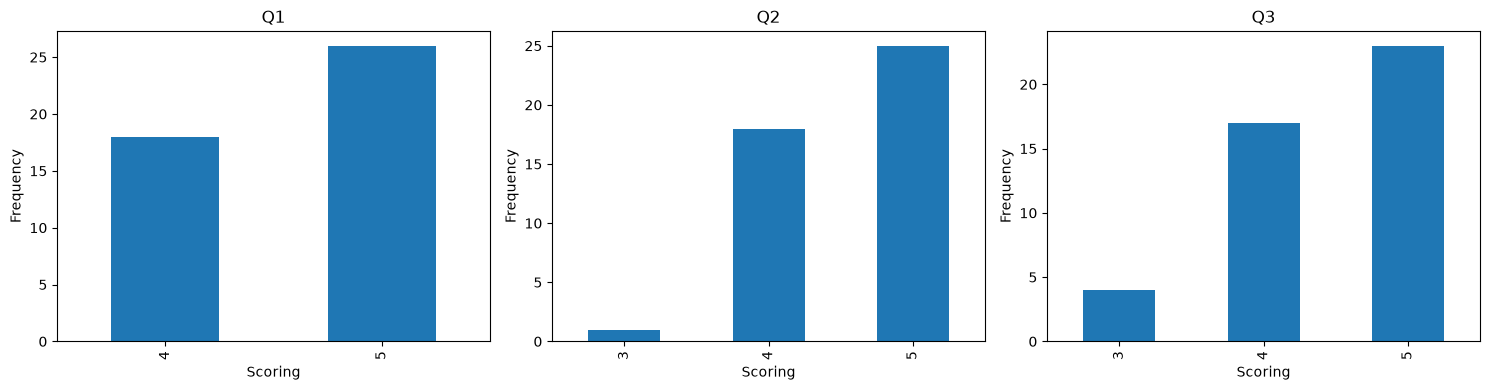

In [89]:

n_cols = len(data.columns)
fig, axes = plt.subplots(nrows=1, ncols=n_cols, figsize=(15, 4))
if n_cols == 1:
    axes = [axes]
for i, col in enumerate(data.columns):
    counts = data[col].value_counts()
    counts = counts.sort_values()
    counts.plot(kind="bar", ax=axes[i], title=f"{col}")
    axes[i].set_ylabel("Frequency")
    axes[i].set_xlabel("Scoring")

plt.tight_layout()
plt.savefig(os.path.join(GRAPH_URL, "Three_Questions_Scoring.png")
    )
plt.show()
